# The Fast Fourier Transform

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/caam37830-sci-comp/notes/blob/main/02_linear_algebra/fft.ipynb)

Recall the discrete Fourier transform (DFT) of a signal $f_0, \dots, f_{N-1}$ from [Convolutions and Fourier Transforms](convolutions.ipynb),

$$ \hat{f}_k = \sum_{n=0}^{N-1} f_n\, e^{-2\pi i k n / N}, \qquad k = 0, \dots, N - 1. $$

With $\omega_N = e^{-2\pi i/N}$, the vector $\hat f$ can be computed using a dense matrix-vector product

$$ \hat f = F_N f, \qquad (F_N)_{kn} = \omega_N^{kn}, $$

and computing the Fourier transform in this way takes $O(N^2)$ operations.  However, it is possible to do much better: the **fast Fourier transform** (FFT) computes a DFT in $O(N\log N)$ operations!  For $N = 10^6$, that is the difference between $10^{12}$ operations and about $2 \times 10^7$.  The algorithm was published by Cooley and Tukey in 1965 (Gauss had found it around 1805, while computing the orbits of asteroids, but it was only published after his death), and it is another one of the [top-10 algorithms of the 20th century](https://archive.siam.org/pdf/news/637.pdf).

This section derives the FFT, implements it in a few lines of NumPy, looks at it as a factorization of $F_N$ into sparse matrices, and shows how to handle lengths that are not powers of 2.

In [1]:
import time

import numpy as np
import scipy.fft
import scipy.sparse as sparse
import matplotlib.pyplot as plt
from sympy import factorint

rng = np.random.default_rng(0)

## The DFT matrix

Here is the DFT straight from the definition.  Since $\omega_N^N = 1$, the exponent $kn$ can be reduced modulo $N$, which keeps the arguments of `exp` small and accurate.

In [2]:
def dft_matrix(N):
    """
    the N x N DFT matrix, F[k, n] = exp(-2 pi i k n / N)
    """
    n = np.arange(N)
    return np.exp(-2j * np.pi * (np.outer(n, n) % N) / N)


N = 16
F = dft_matrix(N)
f = rng.standard_normal(N)
print("F f = fft(f)?       ", np.allclose(F @ f, scipy.fft.fft(f)))
print("conj(F)^T F = N I?  ", np.allclose(F.conj().T @ F, N * np.eye(N)))

F f = fft(f)?        True
conj(F)^T F = N I?   True


The second check says that the columns of $F_N$ are orthogonal, each with squared length $N$.  So $F_N^{-1} = \frac1N \overline{F_N}^T$, and $F_N / \sqrt N$ is a unitary matrix.  The inverse DFT is the DFT with $\omega_N$ replaced by its complex conjugate, $\operatorname{ifft}(x) = \overline{\operatorname{fft}(\overline x)}/N$, so a fast algorithm for $F_N$ is also one for $F_N^{-1}$.

$F_N$ is completely dense: every entry has absolute value 1.  But it is also highly structured.  Its entries are powers of the single number $\omega_N$, and since $\omega_N^N = 1$, only $N$ different values appear among its $N^2$ entries.  Here is the real part of $F_{64}$, whose entries are $\cos(2\pi kn/64)$:

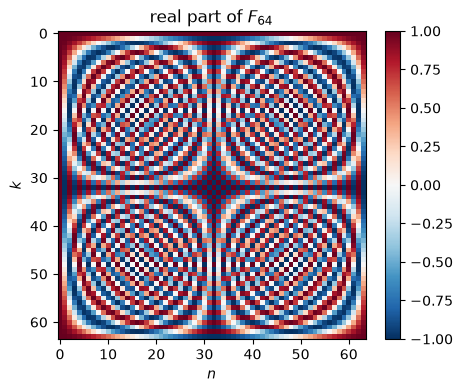

In [3]:
plt.figure(figsize=(5, 4))
plt.imshow(dft_matrix(64).real, cmap='RdBu_r', vmin=-1, vmax=1)
plt.colorbar()
plt.xlabel('$n$')
plt.ylabel('$k$')
plt.title(r'real part of $F_{64}$')
plt.show()

## Derivation of the FFT

Suppose $N$ is even, and split the sum that defines $\hat f_k$ into the terms with an even index $n = 2m$ and those with an odd index $n = 2m + 1$:

$$ \hat f_k = \sum_{m=0}^{N/2-1} f_{2m}\, \omega_N^{2mk} + \omega_N^k \sum_{m=0}^{N/2-1} f_{2m+1}\, \omega_N^{2mk}. $$

Since $\omega_N^2 = e^{-2\pi i/(N/2)} = \omega_{N/2}$, both sums are DFTs of length $N/2$: the first is the DFT $E$ of the even-indexed entries $(f_0, f_2, \dots, f_{N-2})$, and the second the DFT $O$ of the odd-indexed entries $(f_1, f_3, \dots, f_{N-1})$.  So

$$ \hat f_k = E_k + \omega_N^k\, O_k, $$

where $E_k$ and $O_k$ are periodic in $k$ with period $N/2$.  For the second half of the outputs, $E_{k + N/2} = E_k$, $O_{k+N/2} = O_k$, and $\omega_N^{k + N/2} = -\omega_N^k$, so

$$ \hat f_k = E_k + \omega_N^k O_k, \qquad \hat f_{k + N/2} = E_k - \omega_N^k O_k, \qquad k = 0, \dots, N/2 - 1. $$

A DFT of length $N$ therefore takes two DFTs of length $N/2$, plus $N/2$ multiplications by the **twiddle factors** $\omega_N^k$ and $N$ additions.  The pair of formulas that turns $(E_k, O_k)$ into $(\hat f_k, \hat f_{k+N/2})$ is called a **butterfly**, after the shape of its diagram.

If $N$ is a power of 2, we can split the two half-length DFTs in the same way, and so on, until we reach DFTs of length 1, which do nothing: $\hat f_0 = f_0$.

In [4]:
def fft_recursive(f):
    """
    DFT of f by recursive splitting into even and odd entries (radix-2 FFT)

    len(f) must be a power of 2
    """
    N = len(f)
    if N == 1:
        return np.asarray(f, dtype=complex)
    if N % 2 != 0:
        raise ValueError("length must be a power of 2")
    E = fft_recursive(f[0::2])                         # DFT of the even-indexed entries
    O = fft_recursive(f[1::2])                         # DFT of the odd-indexed entries
    w = np.exp(-2j * np.pi * np.arange(N // 2) / N)    # twiddle factors
    return np.concatenate([E + w * O, E - w * O])


f = rng.standard_normal(1024)
print(np.max(np.abs(fft_recursive(f) - scipy.fft.fft(f))))

4.832213032818602e-14


### Operation count

Let $T(N)$ be the number of operations for a DFT of length $N$.  The splitting gives

$$ T(N) = 2\,T(N/2) + O(N), $$

which is the recurrence for mergesort in [Recursion](../01_analysis/recursion.ipynb), and by the master theorem $T(N) = O(N \log N)$.  To count exactly: there are $\log_2 N$ levels of splitting, and the butterflies on each level do $N/2$ complex multiplications and $N$ complex additions in total.  So the FFT takes $\frac{N}{2}\log_2 N$ complex multiplications and $N \log_2 N$ complex additions, against $N^2$ of each for the matrix-vector product.

In [5]:
print(f"{'N':>10} {'N^2':>9} {'(N/2) log2 N':>13} {'ratio':>9}")
for p in [4, 10, 16, 20, 24]:
    N = 2**p
    print(f"{N:10d} {N**2:9.1e} {N // 2 * p:13.1e} {N**2 / (N // 2 * p):9.0f}")

         N       N^2  (N/2) log2 N     ratio
        16   2.6e+02       3.2e+01         8
      1024   1.0e+06       5.1e+03       205
     65536   4.3e+09       5.2e+05      8192
   1048576   1.1e+12       1.0e+07    104858
  16777216   2.8e+14       2.0e+08   1398101


## An iterative FFT

`fft_recursive` spends most of its time on Python function calls and on tiny arrays: half of its calls are on arrays of length 1.  Fast implementations unroll the recursion.

Follow the entries of the input down the recursion.  The first split sorts them by the last binary digit of their index (even before odd), the second split by the next-to-last digit, and so on.  At the bottom they arrive in **bit-reversed** order: position $j$ holds $f_{r(j)}$, where $r(j)$ is $j$ with its $\log_2 N$ binary digits written in reverse order.

In [6]:
def bit_reversal(N):
    """
    the order in which the recursive FFT reaches the entries of an input of
    length N (a power of 2): each index with its binary digits reversed
    """
    p = np.array([0])
    while len(p) < N:
        p = np.concatenate([2 * p, 2 * p + 1])         # even indices first, then odd
    return p


for j, r in enumerate(bit_reversal(8)):
    print(f"position {j} = {j:03b}  holds  f_{r} = f_{r:03b}")

position 0 = 000  holds  f_0 = f_000
position 1 = 001  holds  f_4 = f_100
position 2 = 010  holds  f_2 = f_010
position 3 = 011  holds  f_6 = f_110
position 4 = 100  holds  f_1 = f_001
position 5 = 101  holds  f_5 = f_101
position 6 = 110  holds  f_3 = f_011
position 7 = 111  holds  f_7 = f_111


After this permutation, the butterflies are done bottom-up in $\log_2 N$ stages.  Before the stage with butterflies of size $2m$, the array consists of blocks of length $m$, each holding the DFT of the entries that arrived in it.  The stage combines each pair of neighboring blocks $E$ and $O$ with the twiddle factors $\omega_{2m}^j$, $j = 0, \dots, m - 1$.  If we reshape the array so that each row holds one pair of blocks, each stage is a few whole-array operations:

In [7]:
def fft_iterative(f):
    """
    radix-2 FFT of f without recursion: a bit-reversal permutation followed by
    log2(N) stages of butterflies, each done with whole-array operations

    len(f) must be a power of 2
    """
    N = len(f)
    if N & (N - 1):
        raise ValueError("length must be a power of 2")
    X = np.asarray(f, dtype=complex)[bit_reversal(N)]
    m = 1                                               # length of the blocks to combine
    while m < N:
        X = X.reshape(-1, 2 * m)                        # each row holds a pair of blocks
        w = np.exp(-1j * np.pi * np.arange(m) / m)      # twiddle factors for length 2m
        E, O = X[:, :m], w * X[:, m:]
        X = np.hstack([E + O, E - O])
        m *= 2
    return X.ravel()


f = rng.standard_normal(2**12)
print(np.max(np.abs(fft_iterative(f) - scipy.fft.fft(f))))

1.3101760682293515e-13


Compiled libraries go further.  Some do the butterflies in place, overwriting the input, so that the FFT needs almost no extra memory; others, including PocketFFT, the C++ library behind `scipy.fft`, alternate between the input and a single work array of length $N$, which avoids the bit-reversal permutation altogether.  They combine two or three stages into radix-4 or radix-8 butterflies, which need fewer multiplications, precompute the twiddle factors, and order the operations to make good use of the cache (see [Memory and Performance](memory.ipynb)).  The FFTW library ("the Fastest Fourier Transform in the West") even times several strategies on your machine before choosing one.

## The FFT as a matrix factorization

In matrix form, one level of the splitting says

$$ F_N = \begin{bmatrix} I_{N/2} & \Omega_{N/2} \\ I_{N/2} & -\Omega_{N/2} \end{bmatrix} \begin{bmatrix} F_{N/2} & 0 \\ 0 & F_{N/2} \end{bmatrix} P_N, $$

where $P_N$ is the permutation matrix that moves the even-indexed entries in front of the odd-indexed ones, and $\Omega_{N/2} = \operatorname{diag}(1, \omega_N, \dots, \omega_N^{N/2 - 1})$ holds the twiddle factors.  The first factor, the **butterfly matrix** $B_N$, has only two nonzero entries in each row.  Factoring the two copies of $F_{N/2}$ in the same way, and so on, writes the dense matrix $F_N$ as a product of $\log_2 N$ sparse matrices and the bit-reversal permutation $P$:

$$ F_N = A_{\log_2 N} \cdots A_2\, A_1\, P, \qquad A_s = I_{N/2^s} \otimes B_{2^s}. $$

Here $A_s = \operatorname{diag}(B_{2^s}, \dots, B_{2^s})$ applies the butterflies of size $2^s$ to each block of length $2^s$ ($\otimes$ is the Kronecker product, `scipy.sparse.kron`).  Each factor has $2N$ nonzero entries, so applying all of them takes $O(N \log N)$ operations.  The FFT is a fast way to apply a dense matrix by factoring it into sparse ones, and many other fast transforms work in the same way.

A_4 A_3 A_2 A_1 P = F_16? True


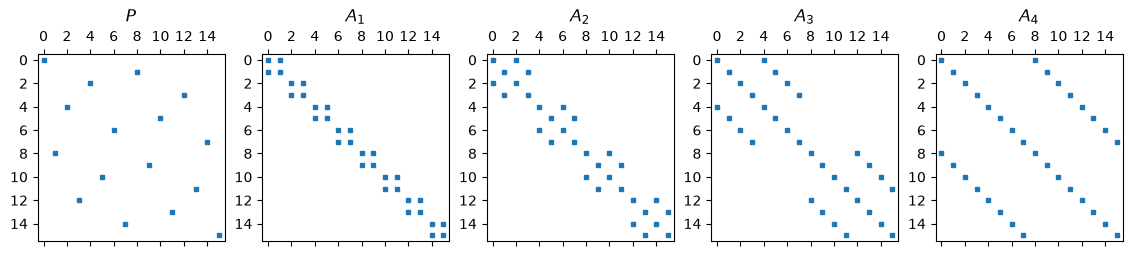

In [8]:
def butterfly_matrix(n):
    """
    the n x n butterfly matrix [[I, W], [I, -W]], with W = diag(exp(-2 pi i j / n)), j < n/2
    """
    W = sparse.diags(np.exp(-2j * np.pi * np.arange(n // 2) / n))
    I = sparse.identity(n // 2)
    return sparse.bmat([[I, W], [I, -W]], format='csr')


N = 16
P = sparse.identity(N, format='csr')[bit_reversal(N)]     # (P f)[j] = f[bit_reversal(N)[j]]
factors = [sparse.kron(sparse.identity(N // 2**s), butterfly_matrix(2**s), format='csr')
           for s in range(1, int(np.log2(N)) + 1)]

product = P.toarray()
for A in factors:
    product = A @ product
print("A_4 A_3 A_2 A_1 P = F_16?", np.allclose(product, dft_matrix(N)))

fig, ax = plt.subplots(1, len(factors) + 1, figsize=(14, 3))
ax[0].spy(P, markersize=3)
ax[0].set_title('$P$')
for s, A in enumerate(factors, start=1):
    ax[s].spy(A, markersize=3)
    ax[s].set_title(f'$A_{s}$')
plt.show()

From left to right, in the order they are applied: the bit-reversal permutation, then butterflies between neighbors, between entries 2 apart, 4 apart, and 8 apart.

## Timing

Here are the four implementations on random vectors of increasing length: the matrix-vector product (not counting the time to build the matrix), the recursive and the iterative FFT, and SciPy's FFT.

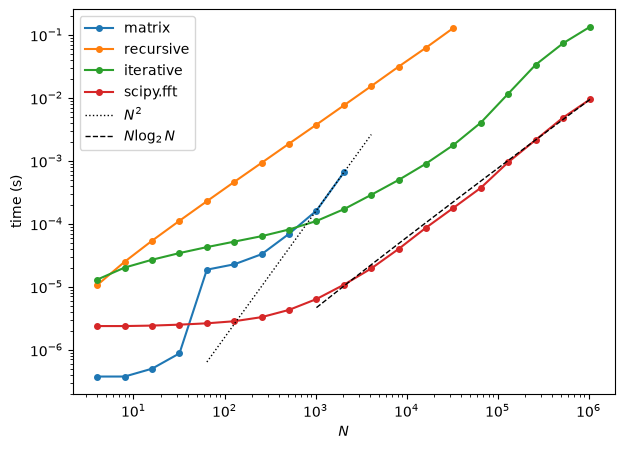

In [9]:
def best_time(func, *args, budget=0.05):
    """
    the shortest time of a call to func(*args), from repeated calls that take
    about `budget` seconds in total (and at least three calls)
    """
    times, total = [], 0.0
    while total < budget or len(times) < 3:
        start = time.perf_counter()
        func(*args)
        times.append(time.perf_counter() - start)
        total += times[-1]
    return min(times)


timings = {'matrix': [], 'recursive': [], 'iterative': [], 'scipy.fft': []}
for p in range(2, 21):
    N = 2**p
    f = rng.standard_normal(N)
    if N <= 2**11:
        F = dft_matrix(N)
        timings['matrix'].append((N, best_time(F.dot, f)))
    if N <= 2**15:
        timings['recursive'].append((N, best_time(fft_recursive, f)))
    timings['iterative'].append((N, best_time(fft_iterative, f)))
    timings['scipy.fft'].append((N, best_time(scipy.fft.fft, f)))

plt.figure(figsize=(7, 5))
for name, data in timings.items():
    Ns, ts = np.array(data).T
    plt.loglog(Ns, ts, 'o-', ms=4, label=name)
N_matrix, t_matrix = timings['matrix'][-1]           # reference lines through the last points
N_fft, t_fft = timings['scipy.fft'][-1]
Ns = 2.0**np.arange(6, 13)
plt.loglog(Ns, t_matrix * (Ns / N_matrix)**2, 'k:', lw=1, label='$N^2$')
Ns = 2.0**np.arange(10, 21)
plt.loglog(Ns, t_fft * Ns * np.log2(Ns) / (N_fft * np.log2(N_fft)), 'k--', lw=1, label=r'$N \log_2 N$')
plt.xlabel('$N$')
plt.ylabel('time (s)')
plt.legend()
plt.show()

For small $N$, every method is dominated by fixed overhead, the cost of calling functions and allocating arrays.  The matrix-vector product, a single call to BLAS, is the fastest method up to $N = 32$ and beats our iterative FFT up to about $N = 1000$, after which its $N^2$ growth takes over.  `scipy.fft` follows the $N \log_2 N$ line for large $N$.  The recursive FFT grows at the same rate, but it makes $2N - 1$ Python function calls and is the slowest method for all but the smallest $N$.  The iterative FFT makes only $\log_2 N$ rounds of whole-array operations, and stays within a factor of about 10 to 15 of `scipy.fft` for large $N$.

## Accuracy

The FFT is not only faster than the matrix-vector product, it is also more accurate.  Each entry of the matrix-vector product is a sum of $N$ rounded products, and the rounding errors in such a sum grow like $\sqrt N$ on average (and like $N$ in the worst case).  Each output of the FFT passes through only $\log_2 N$ butterflies, and its error grows like $\log_2 N$ (see Higham, *Accuracy and Stability of Numerical Algorithms*, chapter 24).  The difference is easiest to see in single precision, against an FFT in double precision as the reference:

In [10]:
print(f"{'N':>5} {'matrix':>9} {'FFT':>9}   relative errors in single precision")
for p in range(6, 14):
    N = 2**p
    f = rng.standard_normal(N).astype(np.float32)
    exact = scipy.fft.fft(f.astype(np.float64))
    F = dft_matrix(N).astype(np.complex64)
    err_matrix = np.linalg.norm(F @ f.astype(np.complex64) - exact) / np.linalg.norm(exact)
    err_fft = np.linalg.norm(scipy.fft.fft(f) - exact) / np.linalg.norm(exact)
    print(f"{N:5d} {err_matrix:9.1e} {err_fft:9.1e}")

    N    matrix       FFT   relative errors in single precision
   64   8.0e-08   7.6e-08
  128   9.1e-08   9.8e-08
  256   1.5e-07   8.6e-08
  512   2.0e-07   9.1e-08
 1024   2.8e-07   1.0e-07
 2048   4.1e-07   1.1e-07


 4096   5.8e-07   1.2e-07


 8192   8.2e-07   1.2e-07


As $N$ grows by a factor of 128, the error of the matrix-vector product grows by a factor of about 10, close to $\sqrt{128} \approx 11$, while the error of the FFT barely changes.  (Single precision has a unit roundoff of $2^{-24} \approx 6 \times 10^{-8}$; see [Bits, Bytes, and Numbers](../00_python/bitsbytes.ipynb).)

## Lengths that are not powers of 2

The even/odd split generalizes.  If $N = N_1 N_2$, splitting the input into $N_1$ interleaved subsequences of length $N_2$ turns a DFT of length $N$ into $N_1$ DFTs of length $N_2$, twiddle factors, and $N_2$ DFTs of length $N_1$.  This is the **mixed-radix** Cooley-Tukey algorithm, and with it any length whose prime factors are all small takes $O(N \log N)$ operations.  A prime length cannot be split, but there are still $O(N\log N)$ algorithms for it (Rader's, and Bluestein's below), with a larger constant.  `scipy.fft` handles every length, but its speed depends on the prime factors of $N$:

In [11]:
print(f"{'N':>6}   {'prime factors':30} time (ms)")
for N in [65536, 59049, 78125, 65540, 65538, 65542, 65537]:
    t = best_time(scipy.fft.fft, rng.standard_normal(N))
    print(f"{N:6d}   {str(factorint(N)):30} {1e3 * t:6.2f}")

     N   prime factors                  time (ms)
 65536   {2: 16}                          0.36
 59049   {3: 10}                          0.35
 78125   {5: 7}                           0.44


 65540   {2: 2, 5: 1, 29: 1, 113: 1}      0.86
 65538   {2: 1, 3: 2, 11: 1, 331: 1}      1.69
 65542   {2: 1, 32771: 1}                 2.52
 65537   {65537: 1}                       2.40


Lengths around $65\,000$ made of 2s, 3s, or 5s all take about the same time.  A length with the prime factors 29 and 113 takes about twice as long, one with the prime factor 331 between four and five times as long, and a prime length, or one with a large prime factor such as $65542 = 2 \cdot 32771$, six or seven times as long.  When you are free to choose the length, as when padding with zeros for a convolution, `scipy.fft.next_fast_len` returns the smallest length at least as large as its argument that has only small prime factors:

In [12]:
N = scipy.fft.next_fast_len(65537)
print(N, factorint(N))

65610 {2: 1, 3: 8, 5: 1}


### Prime lengths: the DFT as a convolution

Bluestein's algorithm turns a DFT of any length into a convolution, which can then be computed with power-of-2 FFTs as in [Convolutions and Fourier Transforms](convolutions.ipynb).  The trick is the identity $kn = \frac12\left(k^2 + n^2 - (k - n)^2\right)$, which gives

$$ \hat f_k = \sum_{n=0}^{N-1} f_n\, \omega_N^{kn} = \omega_N^{k^2/2} \sum_{n=0}^{N-1} \left(f_n\, \omega_N^{n^2/2}\right) \omega_N^{-(k - n)^2/2}, $$

where $\omega_N^{x/2}$ means $e^{-\pi i x/N}$.  The sum is the linear convolution of $a_n = f_n\, \omega_N^{n^2/2}$, $n = 0, \dots, N - 1$, with $b_j = \omega_N^{-j^2/2}$, $j = -(N - 1), \dots, N - 1$, evaluated at $k$.  (A signal like $b_j$, whose frequency grows linearly with $j$, is called a **chirp**.)  Padding both to a power of 2, $M \ge 2N - 1$, and computing the convolution with FFTs of length $M$ takes $O(N \log N)$ operations, whatever $N$ is.  The function below uses nothing but `fft_iterative`, and computes the inverse FFT as $\operatorname{ifft}(x) = \overline{\operatorname{fft}(\overline x)}/M$.

In [13]:
def fft_bluestein(f):
    """
    DFT of f, of any length N, as a convolution computed with power-of-2 FFTs
    """
    N = len(f)
    n = np.arange(N)
    chirp = np.exp(-1j * np.pi * (n * n % (2 * N)) / N)    # omega^(n^2/2), with n^2 reduced mod 2N
    M = 1 << (2 * N - 2).bit_length()                     # a power of 2 that is at least 2N - 1
    a = np.zeros(M, dtype=complex)
    a[:N] = f * chirp
    b = np.zeros(M, dtype=complex)                         # b_j for j = -(N - 1), ..., N - 1,
    b[:N] = np.conj(chirp)                                 # stored circularly: b_j at index j mod M
    b[M - N + 1:] = np.conj(chirp[:0:-1])
    ab_hat = fft_iterative(a) * fft_iterative(b)
    conv = np.conj(fft_iterative(np.conj(ab_hat))) / M     # inverse FFT of length M
    return chirp * conv[:N]


f = rng.standard_normal(65537)
%time f_hat = fft_bluestein(f)
print("relative difference from scipy.fft:", np.max(np.abs(f_hat - scipy.fft.fft(f))) / np.max(np.abs(f_hat)))

CPU times: user 54.6 ms, sys: 39.7 ms, total: 94.4 ms
Wall time: 94.6 ms
relative difference from scipy.fft: 1.7142521659446655e-15


SciPy's `scipy.signal.czt` uses the same idea for the more general chirp z-transform.

## Exercises

### Exercise 1

The DFT of a real vector has conjugate symmetry, $\hat f_{-k} = \overline{\hat f_k}$, so a complex FFT of a real vector wastes about half of its work.  Given two real vectors $x$ and $y$ of length $N$, let $z = x + iy$.  Show that

$$ \hat x_k = \frac{\hat z_k + \overline{\hat z_{-k}}}{2}, \qquad \hat y_k = \frac{\hat z_k - \overline{\hat z_{-k}}}{2i}, $$

with indices modulo $N$, and use this to compute the DFTs of two real vectors with a single complex FFT.  Check against `scipy.fft.fft`.

In [14]:
# Your code here

### Exercise 2

Derive the splitting of a DFT of length $N = 3M$ into three DFTs of length $M$, of the entries $f_{3m}$, $f_{3m+1}$, and $f_{3m+2}$, and write a recursive `fft_radix3` for lengths $N = 3^p$.  Check it against `scipy.fft.fft`.  How many operations does it take?

In [15]:
# Your code here

### Exercise 3

Write an iterative radix-2 FFT that works **in place**, with explicit loops instead of reshaping: swap the entries into bit-reversed order, then do the butterflies of each stage one at a time, overwriting the array.  Compile it with `numba.njit` (see [Vectorization, Numpy Universal Functions](../10_computing/performance/numpy_ufuncs.ipynb)), and compare its speed with `fft_iterative` and `scipy.fft.fft` for $N = 2^{10}, \dots, 2^{22}$.

In [16]:
# Your code here

### Exercise 4

Multiplying two $n$-digit integers by the school method takes $O(n^2)$ operations.  Write the digits of $a$ and $b$ (in base 10, least significant first) as vectors.  The digits of $ab$ come from the convolution of these vectors (see [Convolutions and Fourier Transforms](convolutions.ipynb)), followed by carrying.  Write a function `multiply_fft(a, b)` that computes the convolution with `scipy.fft.rfft`, rounds it to integers, and carries.  Check it against Python's `a * b` for random integers with $10^5$ digits, and compare the times.  (Python's built-in multiplication uses Karatsuba's $O(n^{1.58})$ algorithm.  Converting integers with more than 4300 digits to strings requires `sys.set_int_max_str_digits(0)`.)  Why is it safe to round the floating point convolution to integers, and when would it stop being safe?

In [17]:
# Your code here